In [1]:
import json
from pathlib import Path
from collections import defaultdict

import pandas as pd
import matplotlib.pyplot as plt

# Find the project directory
ROOT = Path.cwd()

if not (ROOT / "data").exists():
    ROOT = ROOT.parent

TRAIN_JSON = (
    ROOT / "data" / "processed" / "trashcan_cleaned_final"
    / "annotations" / "instances_train.json"
)

VAL_JSON = (
    ROOT / "data" / "processed" / "trashcan_cleaned_final"
    / "annotations" / "instances_val.json"
)

print("Training JSON:", TRAIN_JSON)
print("File exists:", TRAIN_JSON.exists())

print("Validation JSON:", VAL_JSON)
print("File exists:", VAL_JSON.exists())

Training JSON: c:\Users\mariem\Documents\trashcan-dl-mlops\data\processed\trashcan_cleaned_final\annotations\instances_train.json
File exists: True
Validation JSON: c:\Users\mariem\Documents\trashcan-dl-mlops\data\processed\trashcan_cleaned_final\annotations\instances_val.json
File exists: True


In [2]:
with open(TRAIN_JSON, "r") as file:
    train_data = json.load(file)

categories = {
    category["id"]: category["name"]
    for category in train_data["categories"]
}

# Count annotations and unique images for each class
annotation_counts = defaultdict(int)
image_counts = defaultdict(set)

for annotation in train_data["annotations"]:

    category_id = annotation["category_id"]
    image_id = annotation["image_id"]

    annotation_counts[category_id] += 1
    image_counts[category_id].add(image_id)

results = []

for category_id, class_name in categories.items():

    results.append({
        "class": class_name,
        "annotations": annotation_counts[category_id],
        "images": len(image_counts[category_id])
    })

df_classes = pd.DataFrame(results)

df_classes = df_classes.sort_values(
    by="annotations",
    ascending=False
).reset_index(drop=True)

df_classes

,class,annotations,images
0,trash_etc,1589,1372
1,trash_plastic,1467,1370
2,trash_metal,908,896
3,trash_wood,285,269
4,trash_fabric,258,213
5,trash_paper,168,142
6,trash_fishing_gear,160,131
7,trash_rubber,107,107


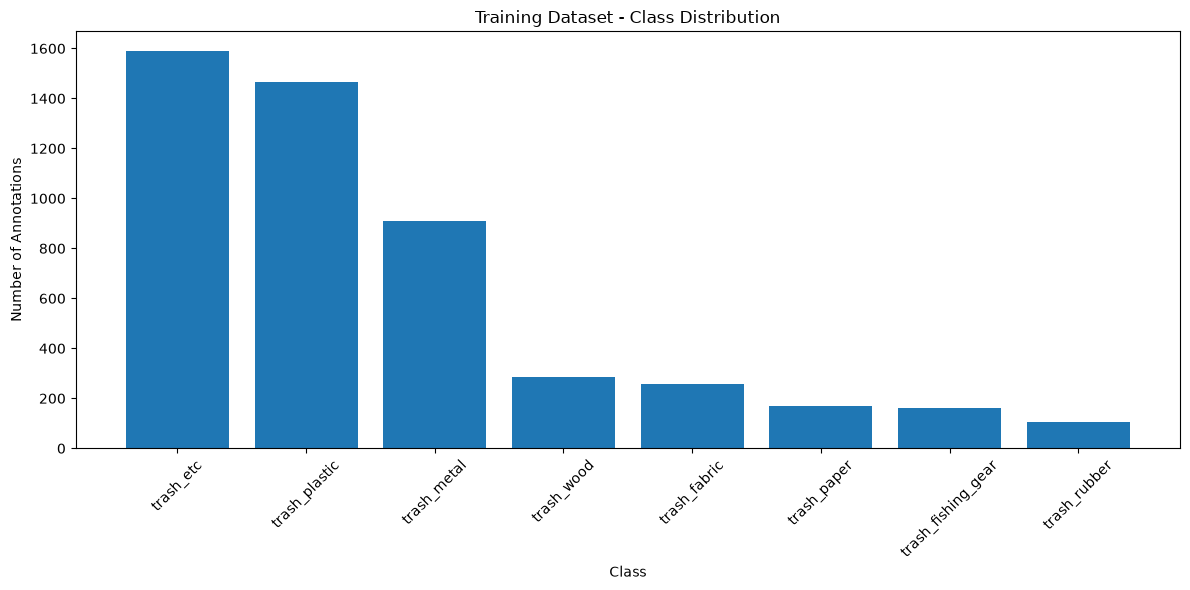

In [3]:
plt.figure(figsize=(12, 6))

plt.bar(
    df_classes["class"],
    df_classes["annotations"]
)

plt.title("Training Dataset - Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

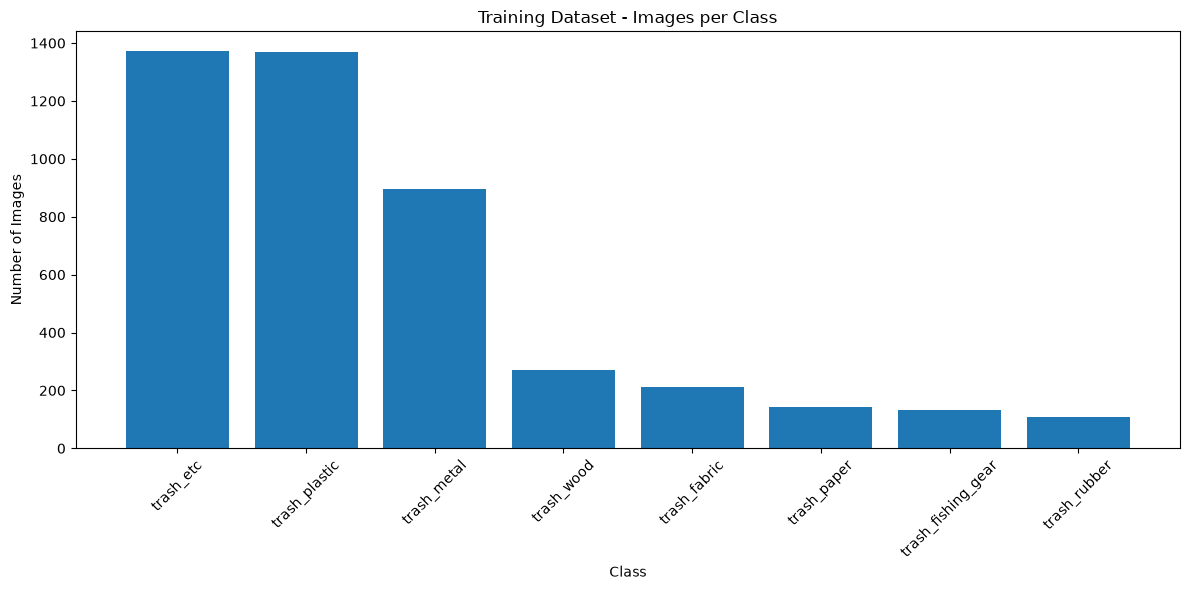

In [4]:
plt.figure(figsize=(12, 6))

plt.bar(
    df_classes["class"],
    df_classes["images"]
)

plt.title("Training Dataset - Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [5]:
total_images = len(train_data["images"])

images_with_objects = set()

for annotation in train_data["annotations"]:
    images_with_objects.add(annotation["image_id"])

negative_images = total_images - len(images_with_objects)

print("Total training images:", total_images)
print("Images containing trash:", len(images_with_objects))
print("Negative images:", negative_images)
print(
    "Negative image percentage:",
    round(negative_images / total_images * 100, 2),
    "%"
)

Total training images: 5233
Images containing trash: 4175
Negative images: 1058
Negative image percentage: 20.22 %


In [6]:
from collections import defaultdict

# Map each image to its classes
image_classes = defaultdict(set)

for annotation in train_data["annotations"]:

    image_id = annotation["image_id"]
    category_id = annotation["category_id"]

    image_classes[image_id].add(category_id)


# Count images containing each combination
combination_counts = defaultdict(int)

for image_id, class_ids in image_classes.items():

    class_names = [
        categories[class_id]
        for class_id in sorted(class_ids)
    ]

    combination = " + ".join(class_names)

    combination_counts[combination] += 1


# Display the 20 most frequent combinations
df_combinations = pd.DataFrame([
    {
        "class_combination": combination,
        "images": count
    }
    for combination, count in combination_counts.items()
])

df_combinations = df_combinations.sort_values(
    by="images",
    ascending=False
)

df_combinations.head(20)

,class_combination,images
0,trash_etc,1212
4,trash_plastic,1171
2,trash_metal,791
6,trash_wood,264
3,trash_fabric,160
11,trash_paper,124
9,trash_rubber,106
7,trash_fishing_gear,72
1,trash_plastic + trash_metal,60
5,trash_etc + trash_plastic,54


In [7]:
rare_classes = [
    "trash_fabric",
    "trash_paper",
    "trash_fishing_gear",
    "trash_rubber"
]

for class_name in rare_classes:

    category_id = next(
        key for key, value in categories.items()
        if value == class_name
    )

    alone = 0
    with_other_classes = 0

    for class_ids in image_classes.values():

        if category_id in class_ids:

            if len(class_ids) == 1:
                alone += 1
            else:
                with_other_classes += 1

    print("\nClass:", class_name)
    print("Images containing only this class:", alone)
    print("Images containing multiple classes:", with_other_classes)


Class: trash_fabric
Images containing only this class: 160
Images containing multiple classes: 53

Class: trash_paper
Images containing only this class: 124
Images containing multiple classes: 18

Class: trash_fishing_gear
Images containing only this class: 72
Images containing multiple classes: 59

Class: trash_rubber
Images containing only this class: 106
Images containing multiple classes: 1


In [8]:
from pathlib import Path

YOLO_ROOT = ROOT / "data" / "processed" / "trashcan_yolo"

train_images = YOLO_ROOT / "images" / "train"
train_labels = YOLO_ROOT / "labels" / "train"

print("Training images:", len(list(train_images.glob("*"))))
print("Training labels:", len(list(train_labels.glob("*.txt"))))

print("Images folder exists:", train_images.exists())
print("Labels folder exists:", train_labels.exists())

Training images: 5233
Training labels: 5233
Images folder exists: True
Labels folder exists: True
